# 할인 유입 고객의 재구독 행동 분석

개인 프로젝트. 할인 코호트의 12월 갱신 인원은 대상을 맞춰 정정하고, 학습 행동은 원본 전처리 CSV 정의를 보존합니다. 공개 출력은 집계만 포함합니다.

## 1. 입력과 기준
2022년 11월 첫 결제·정가 15,920원 플랜 고객을 비교합니다. 갱신은 2022년 12월 고유 고객 기준입니다. 원본 CSV는 공개하지 않습니다.

In [1]:
import os
import pandas as pd
from analysis import load_tables, summarize, save_charts
master, renew = load_tables()
print('마스터 고유 고객:', master.user_id.nunique())
print('마스터 ID 중복:', int(master.user_id.duplicated().sum()))

마스터 고유 고객: 4846
마스터 ID 중복: 0


## 2. 할인 코호트의 갱신 흐름
정상가까지 포함한 886명의 갱신 인원 429명·144명을 할인 797명과 혼용하지 않습니다. 136 / 368이 37.0%의 분모·분자입니다.

In [2]:
result = summarize(master, renew)
print(pd.DataFrame(result['funnel']).round(2).to_string(index=False))
assert [r['users'] for r in result['funnel']] == [797, 368, 136]

    stage  users  denominator    pct
11월 할인 유입    797          797 100.00
12월 갱신 기록    368          797  46.17
   연간권 기록    136          368  36.96


## 3. 원본 CSV 행동 지표
고객별 완주율은 user_content_completion_rate(%)를 평균합니다. 미시작 고객의 원본 0도 그대로 포함합니다. 원시 로그를 새롭게 30일로 자르거나 미시작 고객을 제외하지 않습니다.

In [3]:
print(pd.DataFrame(result['november_discount_comparison']).round(2).to_string(index=False))

 group  users  mean_user_completion_pct  mean_activity_events_30
정상가 고객     89                     14.17                   337.52
 할인 고객    797                     29.98                   445.06


## 4. 상품 기록별 집단 비교
월간권 기록 245명과 연간권 기록 136명 중 13명이 겹칩니다. 아래는 원본 탐색의 상품 기록별 집단 비교이며 서로 배타적인 코호트 분할이 아닙니다. 콘텐츠 수와 30일 활동 지표의 집계 범위가 같다고 가정하지 않습니다.

In [4]:
print(pd.DataFrame(result['groups']).round(2).to_string(index=False))
print('두 상품 기록 고객:', result['audit']['customers_with_both_dec_plans'])

       group  users  mean_start_content_unique  mean_active_days_30  mean_user_completion_pct
12월 갱신 기록 없음    429                       4.26                 6.30                     27.46
   월간권 기록 있음    245                       5.38                 6.71                     28.62
   연간권 기록 있음    136                      11.26                11.25                     40.31
두 상품 기록 고객: 13


## 5. 원본 마스터 전체 요약과 구분
아래 갱신율은 여러 달 마스터의 renewed 열을 사용합니다. 12월 갱신과 다른 정의이며 위 할인 퍼널에 직접 연결하지 않습니다.

In [5]:
print(pd.DataFrame(result['master_rates']).round(2).to_string(index=False))

 has_discount  users  renewed_in_source_master  source_master_renewal_pct
            0   3547                      2240                      63.15
            1   1299                       690                      53.12


## 6. 시각화

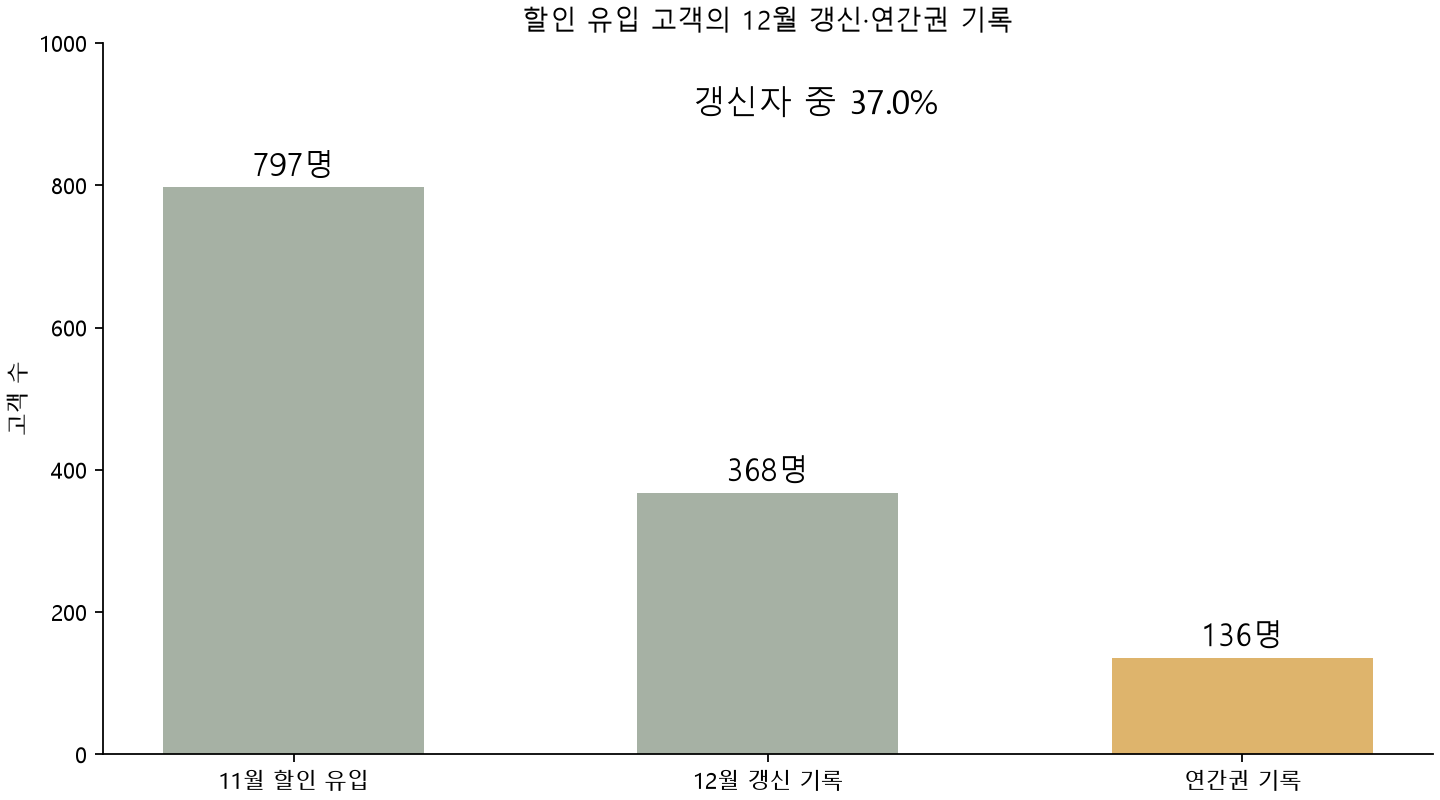

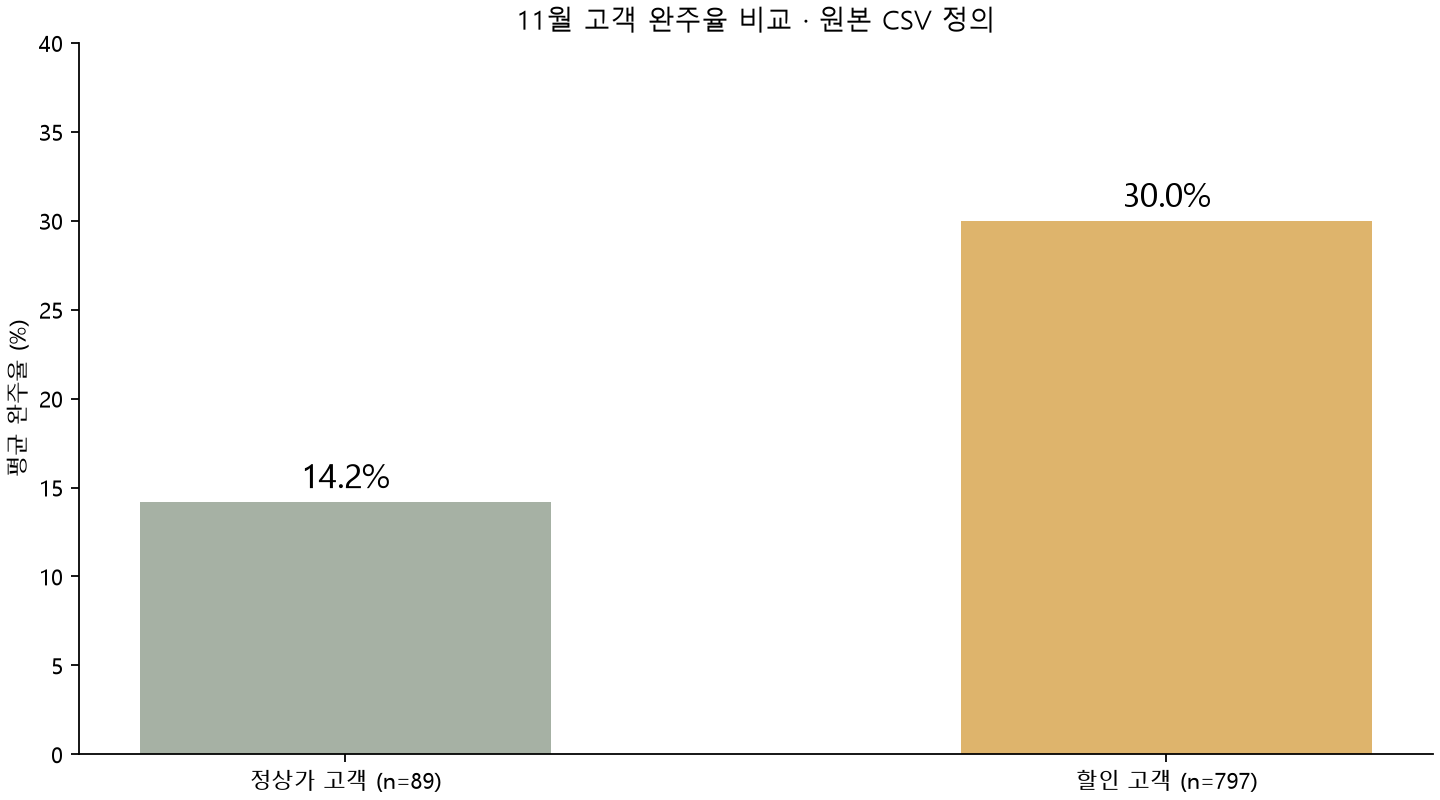

In [6]:
save_charts(result)
from IPython.display import Image, display
display(Image(filename='assets/discount_cohort_funnel.png'))
display(Image(filename='assets/learning_behavior_comparison.png'))

## 7. 해석과 제안
할인 고객은 정상가 고객보다 평균 완주율이 높았고, 12월 갱신자 중 37.0%에게 연간권 기록이 있었습니다. 학습 활동이 이어지는 고객에 대한 연간권 안내 가설을 제안합니다. 실제 안내 시점 이전 행동만으로 대상을 정의하고 무작위 비교 실험으로 효과를 검증해야 합니다.

집단 차이는 인과효과가 아니며 관찰 기간과 갱신 선후관계를 확인하지 않은 결과를 미래 예측 성능으로 주장하지 않습니다. 실제 실험·CRM 실행 성과는 없습니다.